## 📓 Notebook 03: Linear & Logistic Regression

**Skills practiced:** Baseline-before-model comparison, RMSE, reading `.coef_`, `predict()` vs `predict_proba()`, custom classification thresholds.

**Goal:** Predict interest rate with Linear Regression (beating a mean baseline) and predict default with Logistic Regression, comparing hard predictions against probabilities.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report, r2_score


%matplotlib inline

xtrain=pd.read_csv('../data/processed/x_train_scaled.csv')
xtest=pd.read_csv('../data/processed/x_test_scaled.csv')
ytrain=pd.read_csv("../data/processed/Y_train.csv").squeeze()
ytest=pd.read_csv("../data/processed/Y_test.csv").squeeze()
y_train=xtrain['int_rate']
y_test=xtest['int_rate']
x_train=xtrain.drop(columns=['int_rate'])
x_test=xtest.drop(columns=['int_rate'])

In [2]:

baseline_pred=y_train.mean()

baseline_preds = np.full(len(y_test), baseline_pred)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_preds))
print(f'Baseline prediction: {baseline_preds}')
print(f'Baseline RMSE: {baseline_rmse}')

Baseline prediction: [1.1378789e-16 1.1378789e-16 1.1378789e-16 ... 1.1378789e-16 1.1378789e-16
 1.1378789e-16]
Baseline RMSE: 0.9927491287710279


In [3]:
model = LinearRegression()
model.fit(x_train, y_train)
model_preds = model.predict(x_test)

model_rmse = np.sqrt(mean_squared_error(y_test, model_preds))
print(f'Model prediction: {model_preds}')
print(f'Model RMSE: {model_rmse}')


Model prediction: [-0.03292233  0.07079208 -0.29319264 ... -0.23918009 -0.29351297
 -0.51163207]
Model RMSE: 0.9390956933522991


In [4]:
print(round(r2_score(y_test, model_preds), 3))


0.105


In [5]:
coefs = pd.DataFrame({"feature": x_train.columns, "coef": model.coef_})
coefs["abs_coef"] = coefs["coef"].abs()
print(coefs.sort_values("abs_coef", ascending=False).head(20))

                            feature      coef  abs_coef
0                         loan_amnt  0.203714  0.203714
2                        annual_inc -0.173931  0.173931
3                        recoveries  0.172347  0.172347
4                    credit_history -0.137996  0.137996
220        emp_title_superintendent  0.009295  0.009295
18           emp_title_area manager -0.006838  0.006838
232             emp_title_therapist  0.006298  0.006298
135  emp_title_medical technologist  0.006193  0.006193
15          emp_title_administrator -0.005452  0.005452
102            emp_title_hr manager  0.005129  0.005129
117       emp_title_legal secretary -0.005001  0.005001
150             emp_title_paralegal  0.004950  0.004950
30        emp_title_bank of america  0.004832  0.004832
47                    emp_title_cfo -0.004802  0.004802
166             emp_title_principal -0.004752  0.004752
230                emp_title_teller -0.004698  0.004698
111           emp_title_it director -0.004621  0

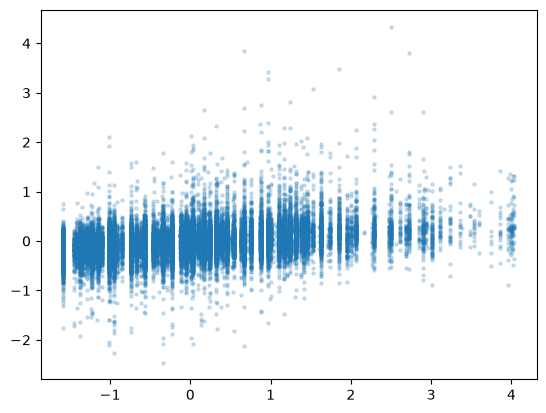

In [6]:
plt.scatter(x=y_test,y=model_preds, alpha=0.2, s=5)
plt.show()

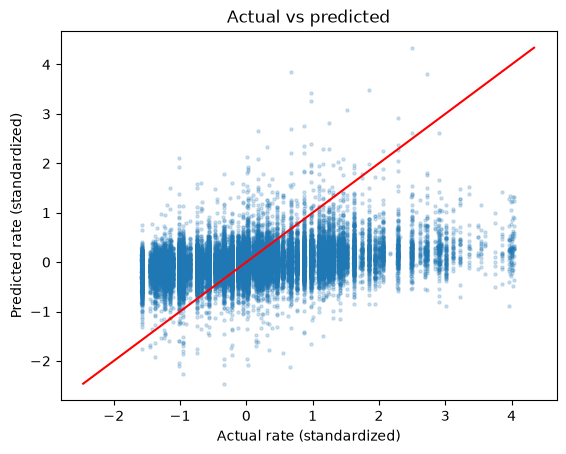

In [7]:
lo = min(y_test.min(), model_preds.min())
hi = max(y_test.max(), model_preds.max())

plt.scatter(y_test, model_preds, alpha=0.2, s=5)
plt.plot([lo, hi], [lo, hi], color="red")
plt.xlabel("Actual rate (standardized)")
plt.ylabel("Predicted rate (standardized)")
plt.title("Actual vs predicted")
plt.show()

In [8]:
model2=LogisticRegression(max_iter=100000, class_weight="balanced")
model2.fit(xtrain, ytrain)

model2_preds=model2.predict(xtest)
print(model2_preds[:5])
print(model2.predict_proba(xtest[:5]).astype(int))

[0 0 0 0 1]
[[0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]]


In [9]:
print(model2.predict_proba(xtest[:5]> 0.3).astype(int))

[[0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]]


In [10]:
print(round(r2_score(ytest, model2_preds), 3))
print(round(accuracy_score(ytest, model2_preds),3))


0.464
0.913


In [11]:
print("defaulted prediction model accuracy:   ", round(accuracy_score(ytest, model2_preds), 3))
print(classification_report(ytest, model2_preds))

defaulted prediction model accuracy:    0.913
              precision    recall  f1-score   support

           0       0.93      0.97      0.95     27127
           1       0.84      0.70      0.77      6906

    accuracy                           0.91     34033
   macro avg       0.89      0.84      0.86     34033
weighted avg       0.91      0.91      0.91     34033



In [12]:
coefs = pd.DataFrame({"feature": xtrain.columns, "coef": model2.coef_[0]})
coefs["abs_coef"] = coefs["coef"].abs()
print(coefs.sort_values("abs_coef", ascending=False).head(20))

                              feature       coef   abs_coef
4                          recoveries  28.859907  28.859907
1                            int_rate   0.603378   0.603378
3                          annual_inc  -0.261449   0.261449
0                           loan_amnt   0.193671   0.193671
118         emp_title_legal secretary  -0.031818   0.031818
2                          emp_length  -0.030342   0.030342
189   emp_title_respiratory therapist  -0.029256   0.029256
140  emp_title_occupational therapist  -0.028975   0.028975
188        emp_title_registered nurse   0.027116   0.027116
69             emp_title_data analyst  -0.026646   0.026646
257     purpose_moving and relocation   0.026446   0.026446
79   emp_title_director of operations   0.025725   0.025725
210                  emp_title_server  -0.025515   0.025515
198               emp_title_secretary  -0.024995   0.024995
85      emp_title_electrical engineer   0.024187   0.024187
65         emp_title_customer service  -